# Day 2: Hidden states

The tokenizer turned text into ids (day 1). The model turns every id into a vector of 768 numbers and refines these vectors layer by layer, letting every token look at the others. The vectors after the last layer are the *hidden states*: one contextual embedding per token.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors

from itg_transformers.config import LABELS, MODEL_NAME
from itg_transformers.data import load_split
from itg_transformers.embeddings import get_embeddings, load_model, similarity
from itg_transformers.tokenization import load_tokenizer, tokenize_texts

tokenizer = load_tokenizer()

## 1. Loading the model

In [2]:
model = load_model()

print("Model:", MODEL_NAME)
print("Class:", type(model).__name__)
print("Device:", model.device)
print("Eval mode:", not model.training)
print(f"Parameters: {model.num_parameters():,}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: distilbert-base-uncased
Class: DistilBertModel
Device: mps:0
Eval mode: True
Parameters: 66,362,880


`AutoModel` works like `AutoTokenizer`: it reads the model config and builds the right class, here `DistilBertModel`. This is the bare encoder. The checkpoint also contains a head for masked word prediction (`vocab_projector` etc.) used in pre-training; `AutoModel` does not need it, which is why loading reports those weights as unexpected.

`model.eval()` switches off dropout. During training dropout randomly zeroes 10% of the values; in eval mode the same text always gives the same vectors.

In [3]:
print(model)

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

Reading the architecture top to bottom:

- **`embeddings`**: `word_embeddings` is a table of 30522 × 768, one vector per token of the vocabulary; `position_embeddings` adds a vector for every position 0-511, otherwise the model would not know the word order.
- **`transformer.layer`**: 6 identical `TransformerBlock`s (BERT has 12). Each one has
  - `attention`: multi-head self-attention, `q_lin`, `k_lin`, `v_lin` build queries, keys and values, `out_lin` merges the 12 heads back (day 3);
  - `ffn`: a feed-forward network applied to every token separately, 768 → 3072 → 768;
  - `LayerNorm` after both, plus residual connections that are not visible in the printout.

Every block takes 768-dimensional vectors and returns vectors of the same size, which is why blocks can be stacked.

In [4]:
config = model.config
print(f"Layers: {config.n_layers}")
print(f"Hidden size: {config.dim}")
print(f"Attention heads: {config.n_heads}")
print(f"Feed-forward size: {config.hidden_dim}")
print(f"Max positions: {config.max_position_embeddings}")

Layers: 6
Hidden size: 768
Attention heads: 12
Feed-forward size: 3072
Max positions: 512


## 2. Hidden states of one text

`tokenize_texts` from day 1 returns a batch of one text. It has to be moved to the same device as the model. `torch.no_grad()` tells PyTorch not to remember intermediate values for gradients: we only read the model, so this saves memory and time.

In [5]:
text = "This movie was absolutely amazing!"
tokens = tokenize_texts([text], tokenizer).to(model.device)

with torch.no_grad():
    outputs = model(**tokens)

print(type(outputs).__name__)
print(outputs.last_hidden_state.shape)

BaseModelOutput
torch.Size([1, 8, 768])


The shape is `[batch_size, sequence_length, hidden_size]`: 1 text, 8 tokens, 768 numbers per token. Every token, `[CLS]` and `[SEP]` included, got its own vector:

In [6]:
token_names = tokenizer.convert_ids_to_tokens(tokens["input_ids"][0].tolist())
for position, (name, vector) in enumerate(
    zip(token_names, outputs.last_hidden_state[0], strict=True)
):
    print(f"{position} {name:12} {vector[:4].cpu().numpy().round(3)} ...")

0 [CLS]        [ 0.068 -0.069  0.192  0.014] ...
1 this         [-0.155 -0.435  0.11   0.151] ...
2 movie        [ 0.441 -0.231  0.039  0.07 ] ...
3 was          [-0.001 -0.536 -0.038  0.154] ...
4 absolutely   [ 0.761 -0.254  0.212  0.107] ...
5 amazing      [0.169 0.128 0.148 0.013] ...
6 !            [ 0.14  -0.191  0.108 -0.411] ...
7 [SEP]        [ 1.006  0.126 -0.269  0.571] ...


### The CLS embedding

Position 0 is `[CLS]`. It is not a word, so its vector is free to collect information from the whole text through attention. Taking it gives one vector per text.

In [7]:
cls_embedding = outputs.last_hidden_state[:, 0, :]
print(f"CLS embedding shape: {cls_embedding.shape}")
print(f"CLS embedding: {cls_embedding[0][:5]}...")

CLS embedding shape: torch.Size([1, 768])


CLS embedding: tensor([ 0.0682, -0.0685,  0.1918,  0.0139, -0.0544], device='mps:0')...


`[:, 0, :]` reads as: every text of the batch, position 0, all 768 numbers.

### Hidden states of every layer

`last_hidden_state` is the output of the last of the 6 blocks. With `output_hidden_states=True` the model also returns the input of the first block (token + position embeddings) and the output of every block:

In [8]:
with torch.no_grad():
    all_layers = model(**tokens, output_hidden_states=True).hidden_states

print(
    f"Tensors: {len(all_layers)} (embeddings + {len(all_layers) - 1} blocks)"
)
print(f"Each of shape: {all_layers[0].shape}")
print(
    "Last equals last_hidden_state: "
    f"{torch.equal(all_layers[-1], outputs.last_hidden_state)}"
)

Tensors: 7 (embeddings + 6 blocks)
Each of shape: torch.Size([1, 8, 768])
Last equals last_hidden_state: True


### Contextual embeddings

The embedding table gives a word the same vector everywhere. The blocks mix in the context. The word `sick` in a negative and in a slang-positive sentence, compared by cosine similarity (1 means same direction, section 5 explains it in detail):

In [9]:
sentences = ["I feel sick today", "that trick was sick"]
batch = tokenize_texts(sentences, tokenizer).to(model.device)
sick_id = tokenizer.get_vocab()["sick"]
positions = batch["input_ids"].eq(sick_id).nonzero()

with torch.no_grad():
    layers = model(**batch, output_hidden_states=True).hidden_states

for layer, states in enumerate(layers):
    first, second = (states[row, column] for row, column in positions)
    cosine = torch.cosine_similarity(first, second, dim=0).item()
    name = "embeddings" if layer == 0 else f"block {layer}"
    print(f"{name:10} similarity of 'sick' vectors: {cosine:.3f}")

embeddings similarity of 'sick' vectors: 0.975
block 1    similarity of 'sick' vectors: 0.899
block 2    similarity of 'sick' vectors: 0.810
block 3    similarity of 'sick' vectors: 0.788
block 4    similarity of 'sick' vectors: 0.762
block 5    similarity of 'sick' vectors: 0.782
block 6    similarity of 'sick' vectors: 0.661


Even at the embedding layer the two vectors are not identical: the token is the same, but its position differs and position embeddings are added. After that every block pulls the two meanings further apart, down to 0.66 after the last block. This is what *contextual* means: the vector of a token depends on the whole sentence.

## 3. `get_embeddings`

Section 2 for many texts at once: `get_embeddings` cuts the texts into batches, runs each through `tokenize_texts` (day 1) and the model, keeps the `[CLS]` vector and moves it to the CPU as a NumPy array. The result has one row per text.

In [10]:
tweets = load_split("train")["text"].head(100).tolist()
tweet_embeddings = get_embeddings(tweets, tokenizer, model)

print(f"Shape: {tweet_embeddings.shape}")
print(f"Type: {type(tweet_embeddings).__name__}, {tweet_embeddings.dtype}")
print(f"First tweet, first 5 values: {tweet_embeddings[0, :5].round(4)}")

Shape: (100, 768)
Type: ndarray, float32
First tweet, first 5 values: [-0.1895 -0.3113 -0.1484 -0.045  -0.1966]


Thanks to `attention_mask`, the embedding of a text does not depend on its neighbours in the batch. Batch size 1 means no padding at all, batch size 32 pads every tweet to the longest one:

In [11]:
alone = get_embeddings(tweets[:8], tokenizer, model, batch_size=1)
together = get_embeddings(tweets[:8], tokenizer, model, batch_size=8)
print(f"Largest difference: {abs(alone - together).max():.1e}")

Largest difference: 4.8e-06


The difference is float rounding, not a change in meaning.

Batch size is a trade-off between speed and memory. Time for 1000 tweets:

In [12]:
thousand = load_split("train")["text"].head(1000).tolist()
get_embeddings(thousand[:64], tokenizer, model)  # warm-up

timings = {}
for batch_size in [1, 8, 32, 128]:
    start = time.perf_counter()
    get_embeddings(thousand, tokenizer, model, batch_size=batch_size)
    timings[batch_size] = time.perf_counter() - start
pd.Series(timings, name="seconds").rename_axis("batch_size").round(2)

batch_size
1      4.59
8      1.55
32     1.30
128    1.31
Name: seconds, dtype: float64

Batches of one leave most of the GPU idle. Beyond some size the gain flattens out, while memory keeps growing. 32 is the default of `get_embeddings`.

## 4. Testing on several texts

In [13]:
texts = [
    "This movie was absolutely amazing!",
    "Terrible movie, waste of time.",
    "Pretty good, I liked it.",
    "Boring and too long.",
]
embeddings = get_embeddings(texts, tokenizer, model)

print(f"Embeddings shape: {embeddings.shape}")
print(f"Expected: (4, {model.config.hidden_size}) for DistilBERT")
assert embeddings.shape == (len(texts), model.config.hidden_size)

Embeddings shape: (4, 768)
Expected: (4, 768) for DistilBERT


Every text, whatever its length, became a vector of the same size. Texts of different length can now be compared and fed to an ordinary classifier (day 4). A quick look at the vectors:

In [14]:
pd.DataFrame(
    {
        "text": texts,
        "tokens": [len(tokenizer.tokenize(text)) + 2 for text in texts],
        "norm": (embeddings**2).sum(axis=1) ** 0.5,
        "mean": embeddings.mean(axis=1),
        "min": embeddings.min(axis=1),
        "max": embeddings.max(axis=1),
    }
).round(3)

,text,tokens,norm,mean,min,max
0,This movie was absolutely amazing!,8,12.952,-0.010,-7.780,3.556
1,"Terrible movie, waste of time.",9,12.618,-0.009,-7.380,3.559
2,"Pretty good, I liked it.",9,12.812,-0.010,-8.184,3.509
3,Boring and too long.,7,12.880,-0.009,-7.788,3.716


The vectors look alike: similar length (norm), mean and range. Even the minimum is about -7.8 everywhere, which hints that it is always the same coordinate. On the 100 train tweets from section 3:

In [15]:
lowest = pd.Series(tweet_embeddings.argmin(axis=1)).value_counts()
print(f"Coordinate holding the minimum: {lowest.to_dict()}")

dim = lowest.index[0]
squared = tweet_embeddings**2
share = (squared[:, dim] / squared.sum(axis=1)).mean()
print(f"Coordinate {dim} holds {share:.0%} of the squared vector length")

Coordinate holding the minimum: {752: 98, 308: 2}
Coordinate 752 holds 25% of the squared vector length


One coordinate out of 768 is large and negative for every text. This is a known property of BERT-like models, so-called *outlier dimensions*. It carries no meaning about the text, yet it makes all vectors point roughly the same way. Keep it in mind for section 5.

## 5. Text similarity

Cosine similarity compares the *direction* of two vectors and ignores their length: 1 means the same direction, 0 means perpendicular (unrelated), -1 means opposite.

In [16]:
sim1 = similarity("Great movie!", "Amazing film!", tokenizer, model)
sim2 = similarity("Great movie!", "Terrible film!", tokenizer, model)

print(f"Similar texts: {sim1:.3f}")
print(f"Different texts: {sim2:.3f}")

Similar texts: 0.995
Different texts: 0.984


The similar pair does score higher, but the opposite pair is almost as close. All pairs of the four texts from section 4:

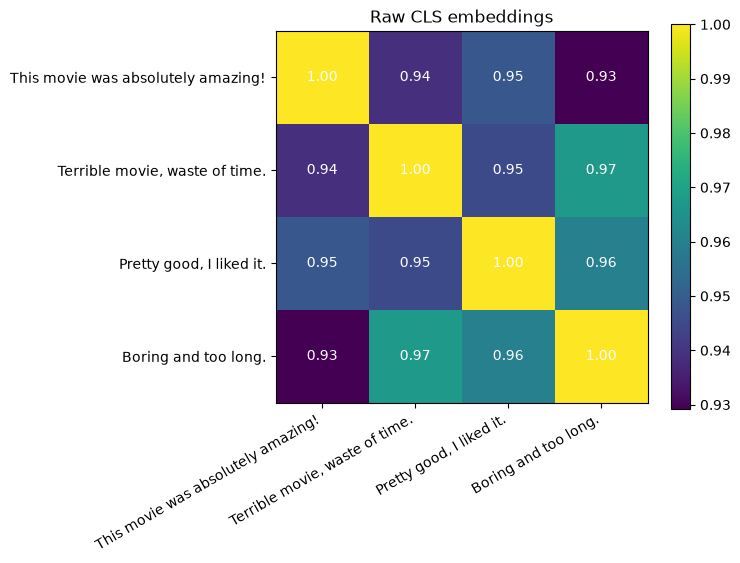

In [17]:
def plot_similarity(matrix: np.ndarray, labels: list[str], title: str) -> None:
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(matrix, cmap="viridis")
    ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    for row in range(len(labels)):
        for column in range(len(labels)):
            ax.text(
                column,
                row,
                f"{matrix[row, column]:.2f}",
                ha="center",
                va="center",
                color="white",
            )
    fig.colorbar(image)
    ax.set_title(title)
    plt.show()


plot_similarity(cosine_similarity(embeddings), texts, "Raw CLS embeddings")

Everything is between 0.93 and 0.97. To see what "high" means for this model, the same measure for 1000 random train tweets, which mostly have nothing to do with each other:

In [18]:
random_tweets = (
    load_split("train")["text"].sample(1000, random_state=0).tolist()
)
random_embeddings = get_embeddings(random_tweets, tokenizer, model)

pairs = np.triu_indices(len(random_tweets), k=1)
random_similarity = cosine_similarity(random_embeddings)[pairs]
print(f"Random tweet pairs: mean {random_similarity.mean():.3f}")
print(f"Least similar pair: {random_similarity.min():.3f}")

Random tweet pairs: mean 0.881
Least similar pair: 0.586


Two unrelated tweets score 0.88 on average. All CLS vectors live in a narrow cone (the model is *anisotropic*), partly because of the outlier coordinate from section 4. A common fix is centering: subtract the mean embedding of a corpus, so that only what makes a text different from a typical tweet is compared.

Random tweet pairs after centering: mean 0.001


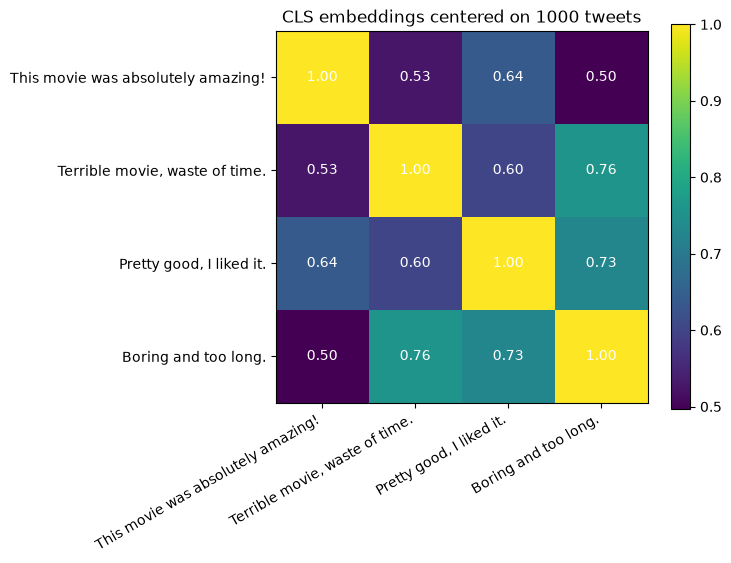

In [19]:
mean_embedding = random_embeddings.mean(axis=0)
centered_random = cosine_similarity(random_embeddings - mean_embedding)[pairs]
print(f"Random tweet pairs after centering: mean {centered_random.mean():.3f}")

plot_similarity(
    cosine_similarity(embeddings - mean_embedding),
    texts,
    "CLS embeddings centered on 1000 tweets",
)

In [20]:
for other in ["Amazing film!", "Terrible film!"]:
    pair = get_embeddings(["Great movie!", other], tokenizer, model)
    raw = cosine_similarity(pair)[0, 1]
    centered = cosine_similarity(pair - mean_embedding)[0, 1]
    print(
        f"'Great movie!' vs {other!r}: raw {raw:.3f}, centered {centered:.3f}"
    )

'Great movie!' vs 'Amazing film!': raw 0.995, centered 0.965
'Great movie!' vs 'Terrible film!': raw 0.984, centered 0.882


After centering unrelated tweets average 0, and the gap between "Amazing film!" and "Terrible film!" grows from about 0.01 to about 0.08. In the centered matrix the closest text to "amazing" is "pretty good" and the closest to "terrible" is "boring", so some sentiment is there. But "pretty good" is closer to "boring" (0.73) than to "amazing" (0.64), and the opposite film review stays far more similar than an unrelated tweet.

The pre-trained model groups texts by topic and form much more than by sentiment: it was never trained to care about sentiment. Day 4 checks how much sentiment a classifier can still read from these vectors, day 5 teaches the model to put it first.

## 6. Bonus: do classes separate without training?

1000 train tweets of every class, so that no class dominates the picture. 768 dimensions are squeezed into 2 in two ways: PCA keeps the directions of largest spread, t-SNE tries to keep neighbours next to each other.

In [21]:
sample = (
    load_split("train")
    .groupby("label")
    .sample(1000, random_state=0)
    .reset_index(drop=True)
)
sample_embeddings = get_embeddings(sample["text"].tolist(), tokenizer, model)
sample_labels = sample["label"].to_numpy()

pca = PCA(n_components=2).fit(sample_embeddings)
projections = {
    "PCA": pca.transform(sample_embeddings),
    "t-SNE": TSNE(n_components=2, init="pca", random_state=0).fit_transform(
        sample_embeddings
    ),
}
kept = pca.explained_variance_ratio_.sum()
print(f"Variance kept by 2 PCA components: {kept:.0%}")

Variance kept by 2 PCA components: 18%


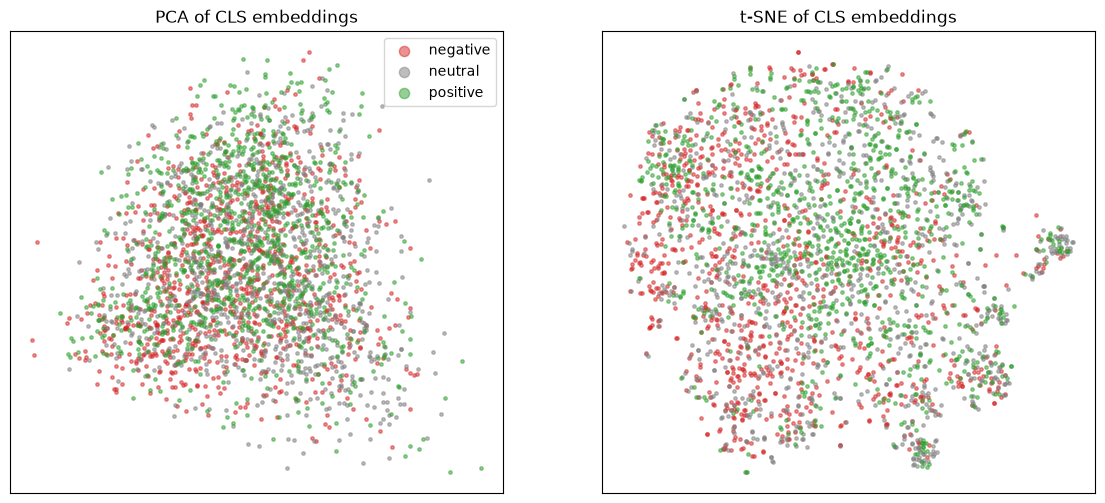

In [22]:
colors = {"negative": "#d62728", "neutral": "#7f7f7f", "positive": "#2ca02c"}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (method, points) in zip(axes, projections.items(), strict=True):
    for label, name in LABELS.items():
        mask = sample_labels == label
        ax.scatter(
            *points[mask].T, s=6, alpha=0.5, color=colors[name], label=name
        )
    ax.set_title(f"{method} of CLS embeddings")
    ax.set_xticks([])
    ax.set_yticks([])
axes[0].legend(markerscale=3)
plt.show()

A picture can mislead, so a number: for every tweet take its 10 nearest neighbours by centered cosine similarity and count how many share its label. With balanced classes, random neighbours would agree 33% of the time.

In [23]:
centered = sample_embeddings - sample_embeddings.mean(axis=0)
neighbours = NearestNeighbors(n_neighbors=11, metric="cosine").fit(centered)
indices = neighbours.kneighbors(centered, return_distance=False)[:, 1:]
same_label = sample_labels[indices] == sample_labels[:, None]

agreement = {
    name: float(same_label[sample_labels == label].mean())
    for label, name in LABELS.items()
}
agreement["all"] = float(same_label.mean())
agreement["chance"] = 1 / len(LABELS)
pd.Series(agreement, name="same-label neighbours").round(3)

negative    0.476
neutral     0.388
positive    0.462
all         0.442
chance      0.333
Name: same-label neighbours, dtype: float64

There is a signal, but a weak one. The clouds overlap almost completely in both projections, and only 44% of neighbours share the label against 33% by chance. Neutral is the hardest class, as expected after the EDA. Sentiment is only one of many things these vectors encode, and not the main one. Day 4 trains a classifier on top of them, which can pick out the sentiment-related directions instead of treating all 768 dimensions equally.